In [1]:
%reset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dnaMD
import fileinput as fi
import scipy
from scipy.optimize import curve_fit
from scipy.stats import linregress
from pylab import *
from tabulate import tabulate
%matplotlib inline

from IPython.display import display, HTML

display(HTML(data="""
<style>
    div#notebook-container    { width: 99%; }
    div#menubar-container     { width: 65%; }
    div#maintoolbar-container { width: 99%; }
</style>
"""))


def rm_neun(vari):
    indizes = np.array([])
    for x in range(len(vari)):
        nmmr = np.where(vari[x] == 99.99)
        neg = np.where(vari[x]<-100)
        indizes = np.append(indizes,nmmr)
        #indizes = np.append(indizes,neg)

    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for d in range(len(vari)):
        for y in range(len(indexes)):
            #print(indexes[y])
            vari[d] = np.delete(vari[d],indexes[y])
            
    return vari

Once deleted, variables cannot be recovered. Proceed (y/[n])? y


In [2]:
#rangenRad = [4,12]
#rangenRad = [7,8]
rangenRad= [1,19]

OL3Cm=dnaMD.DNA(20); OL3Cmrad = dnaMD.DNA(20); OL3Cmprop = dnaMD.DNA(20) 

#OL3Cm.set_base_step_parameters('_marcel_sim/tip3p/L-BPH_CmTip3p.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/tip3p/L-BP_CmTip3p.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/HelixRad_CmTip3p.dat',atomname='C1*',bp=[1,19],bp_range=True)
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/HelixRad_CmTip3p.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3Cm.set_base_step_parameters('_marcel_sim/tip3p/100mM_250ns/L-BPH_Cmtip3p250.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/tip3p/100mM_250ns/L-BP_Cmtip3p250.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/100mM_250ns/HelixRad_Cmtip3p250.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3Cm.set_base_step_parameters('_marcel_sim/tip3p/100mM_400ns/L-BPH_Cmtip3p400.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/tip3p/100mM_400ns/L-BP_Cmtip3p400.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/100mM_400ns/HelixRad_Cmtip3p400.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3Cm.set_base_step_parameters('_marcel_sim/tip3p/100mM_650ns/L-BPH_Cmtip3p650.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/tip3p/100mM_650ns/L-BP_Cmtip3p650.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/100mM_650ns/HelixRad_Cmtip3p650.dat',atomname='C1*',bp=rangenRad,bp_range=True)



#OL3Cm.set_base_step_parameters('_marcel_sim/tip3p/100mM_1000ns/L-BPH_Cmtip3p1000.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/tip3p/100mM_1000ns/L-BP_Cmtip3p1000.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/tip3p/100mM_1000ns/HelixRad_Cmtip3p1000.dat',atomname='C1*',bp=rangenRad,bp_range=True)


OL3Cm.set_base_step_parameters('_marcel_sim/RNA8_tip3p/L-BPH_Cm8tip3p.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
OL3Cmprop.set_base_pair_parameters('_marcel_sim/RNA8_tip3p/L-BP_Cm8tip3p.dat',parameters='all',bp=[1,20],bp_range=True);
OL3Cmrad.set_helical_radius('_marcel_sim/RNA8_tip3p/HelixRad_Cm8tip3p.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3Cm.set_base_step_parameters('_marcel_sim/RNA14_tip3p/L-BPH_Cm14tip3p.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/RNA14_tip3p/L-BP_Cm14tip3p.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/RNA14_tip3p/HelixRad_Cm14tip3p.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3Cm.set_base_step_parameters('_marcel_sim/RNA15_tip3p/L-BPH_Cm15tip3p.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) ;
#OL3Cmprop.set_base_pair_parameters('_marcel_sim/RNA15_tip3p/L-BP_Cm15tip3p.dat',parameters='all',bp=[1,20],bp_range=True);
#OL3Cmrad.set_helical_radius('_marcel_sim/RNA15_tip3p/HelixRad_Cm15tip3p.dat',atomname='C1*',bp=rangenRad,bp_range=True)

 
OL3 = dnaMD.DNA(20); OL3rad = dnaMD.DNA(20);OL3prop = dnaMD.DNA(20) 

OL3.set_base_step_parameters('ol3-odd-v2/L-BPH_ol3.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
#OL3.set_base_step_parameters('ol3_even_new/L-BPH_ol3evnew.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
#OL3.set_base_step_parameters('_marcel_sim/OL3_even_MHrun/L-BPH_evenMHrun.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
#OL3.set_base_step_parameters('ol3-odd-v2/L-BPS_ol3.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=False) 

OL3rad.set_helical_radius('ol3-odd-v2/HelixRad_ol3.dat',atomname='C1*',bp=[1,19],bp_range=True)
#OL3rad.set_helical_radius('ol3_even_new/HelixRad_ol3evnew.dat',atomname='C1*',bp=[1,19],bp_range=True)
#OL3rad.set_helical_radius('_marcel_sim/OL3_even_MHrun/HelixRad_evenMHrun.dat',atomname='C1*',bp=rangenRad,bp_range=True)

#OL3prop.set_base_pair_parameters('ol3_even_new/L-BP_ol3evnew.dat',parameters='all',bp=[1,20],bp_range=True)
#OL3prop.set_base_pair_parameters('_marcel_sim/OL3_even_MHrun/L-BP_evenMHrun.dat',parameters='all',bp=[1,20],bp_range=True)
OL3prop.set_base_pair_parameters('ol3-odd-v2/L-BP_ol3.dat',parameters='all',bp=[1,20],bp_range=True)

rangen=[1,19]
#rangen = [3,17]
#rangen = [9,12]
#rangen = [5,16]
#rangen = [6,15] 
#propl = [1]
proplrange = [1,20]
#proplrange =rangen


OL3Cmrise, bp_idx = OL3Cm.get_parameters('h-rise',rangen,bp_range=True); 
OL3Cmtwist, bp_idx = OL3Cm.get_parameters('h-twist',rangen,bp_range=True);
OL3Cmx, bp_idx = OL3Cm.get_parameters('x-disp',rangen,bp_range=True);
OL3Cmy, bp_idx = OL3Cm.get_parameters('y-disp',rangen,bp_range=True);
OL3Cminc, bp_idx = OL3Cm.get_parameters('inclination',rangen,bp_range=True);
OL3Cmradius1, bp_idx = OL3Cmrad.get_parameters('radius s-1',rangenRad,bp_range=True); 
#OL3Cmpropeller, bp_idx = OL3Cmprop.get_parameters('propeller',rangen,bp_range=True); 
OL3Cmpropeller, bp_idx = OL3Cmprop.get_parameters('propeller',proplrange,bp_range=True); 
#OL3Cmpropeller, bp_idx  = OL3Cmprop.get_parameters('propeller',propl,bp_range=False); 
 
OL3rise, bp_idx = OL3.get_parameters('h-rise',rangen,bp_range=True);
OL3twist, bp_idx = OL3.get_parameters('h-twist',rangen,bp_range=True);
OL3x, bp_idx = OL3.get_parameters('x-disp',rangen,bp_range=True);
OL3y, bp_idx = OL3.get_parameters('y-disp',rangen,bp_range=True);
OL3inc, bp_idx = OL3.get_parameters('inclination',rangen,bp_range=True);
OL3radius1, bp_idx = OL3rad.get_parameters('radius s-1',rangenRad,bp_range=True); 
#OL3propeller, bp_idx = OL3prop.get_parameters('propeller',rangen,bp_range=True); 
OL3propeller, bp_idx = OL3prop.get_parameters('propeller',proplrange,bp_range=True); 
#OL3propeller, bp_idx = OL3prop.get_parameters('propeller',propl,bp_range=False); 

#OL3Cmradius1 = OL3Cmradius1[4:16]
#OL3radius1 = OL3radius1[4:16]


Reading file : _marcel_sim/RNA8_tip3p/L-BPH_Cm8tip3p.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2217

Reading file : _marcel_sim/RNA8_tip3p/L-BP_Cm8tip3p.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2217

Reading file : _marcel_sim/RNA8_tip3p/HelixRad_Cm8tip3p.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2217

Reading file : ol3-odd-v2/L-BPH_ol3.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : ol3-odd-v2/HelixRad_ol3.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001

Reading file : ol3-odd-v2/L-BP_ol3.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001


In [21]:
rangen=[1,19]
OL3Cmgroove = dnaMD.DNA(20);
params = [ 'minor groove', 'minor groove refined', 'major groove', 'major groove refined' ]
OL3Cmgroove.set_major_minor_groove('_marcel_sim/OL3_odd_MHrun/MGroove_oddMHrun.dat',bp_step = rangen,parameters=params,step_range = True)

major, bp_idx = OL3Cmgroove.get_parameters('major groove',rangen,bp_range = True)
major_refined, bp_idx = OL3Cmgroove.get_parameters('major groove refined',rangen,bp_range = True)
minor, bp_idx = OL3Cmgroove.get_parameters('minor groove',rangen,bp_range = True)
minor_refined, bp_idx = OL3Cmgroove.get_parameters('minor groove refined',rangen,bp_range = True)

#nm = 15
#folder = '_marcel_sim/RNA'+str(nm)+'_tip3p/'
folder = '_marcel_sim/OL3_odd_MHrun/'
np.savetxt(folder+'RNA'+str(nm)+'_major.txt',np.array(major))
np.savetxt(folder+'RNA'+str(nm)+'_major_refined.txt',np.array(major_refined))
np.savetxt(folder+'RNA'+str(nm)+'_minor.txt',np.array(minor))
np.savetxt(folder+'RNA'+str(nm)+'_minor_refined.txt',np.array(minor_refined))


Reading file : _marcel_sim/OL3_odd_MHrun/MGroove_oddMHrun.dat
Reading frame 4000
Finished reading.... Total number of frame read =  4205


In [3]:
nm = 8
folder = '_marcel_sim/RNA'+str(nm)+'_tip3p/'
#folder ='_marcel_sim/tip3p/'
np.savetxt(folder+'RNA'+str(nm)+'_Cm_rise.txt',np.array(OL3Cmrise))
np.savetxt(folder+'RNA'+str(nm)+'_Cm_twist.txt',np.array(OL3Cmtwist))
np.savetxt(folder+'RNA'+str(nm)+'_Cm_radius.txt',np.array(OL3Cmradius1))
np.savetxt(folder+'RNA'+str(nm)+'_Cm_inclination.txt',np.array(OL3Cminc))
np.savetxt(folder+'RNA'+str(nm)+'_Cm_propeller.txt',np.array(OL3Cmpropeller))

In [18]:
folder = 'ol3-odd-v2/'
seq = "odd_LSrun"
"""
np.savetxt(folder+'RNA_OL3_rise.txt',np.array(OL3rise))
np.savetxt(folder+'RNA_OL3_twist.txt',np.array(OL3twist))
np.savetxt(folder+'RNA_OL3_radius.txt',np.array(OL3radius1))
np.savetxt(folder+'RNA_OL3_inclination.txt',np.array(OL3inc))
np.savetxt(folder+'RNA_OL3_propeller.txt',np.array(OL3propeller))
"""
np.savetxt(folder+'RNA_OL3'+seq+'_rise.txt',np.array(OL3rise))
np.savetxt(folder+'RNA_OL3'+seq+'_twist.txt',np.array(OL3twist))
np.savetxt(folder+'RNA_OL3'+seq+'_radius.txt',np.array(OL3radius1))
np.savetxt(folder+'RNA_OL3'+seq+'_inclination.txt',np.array(OL3inc))
np.savetxt(folder+'RNA_OL3'+seq+'_propeller.txt',np.array(OL3propeller))

In [50]:
np.shape(np.array(OL3Cmpropeller))

(20, 8902)

OL3: -0.081     ; r-value: -0.56
OL3 Cm: -0.082  ; r-value: -0.5

           OL3          OL3 Cm
---------  -----------  -----------
twist      31.7 ± 1.0   30.4 ± 1.0
h-rise     2.84 ± 0.2   2.97 ± 0.2
propeller  -11.1 ± 2.5  -7.6 ± 2.7
rad        8.71 ± 0.4   7.98 ± 28.3
inc        11.6 ± 3.2   9.0 ± 3.3


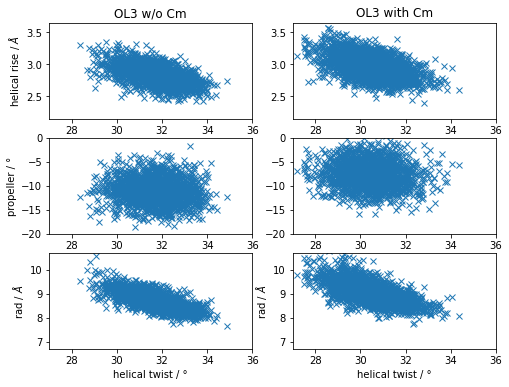

In [45]:
OL3Cmrise = rm_neun(OL3Cmrise); avg_OL3Cmrise = np.mean(OL3Cmrise, axis=0)
OL3Cmtwist = rm_neun(OL3Cmtwist); avg_OL3Cmtwist = np.mean(OL3Cmtwist, axis=0)
OL3Cmx = rm_neun(OL3Cmx); avg_OL3Cmx = np.mean(OL3Cmx, axis=0)
OL3Cmy = rm_neun(OL3Cmy); avg_OL3Cmy = np.mean(OL3Cmy, axis=0)
OL3Cminc = rm_neun(OL3Cminc); avg_OL3Cminc = np.mean(OL3Cminc, axis=0)
OL3Cmradius1 = rm_neun(OL3Cmradius1); avg_OL3Cmradius1 = np.mean(OL3Cmradius1, axis=0)
OL3Cmpropeller= rm_neun(OL3Cmpropeller); avg_OL3Cmpropeller= np.mean(OL3Cmpropeller, axis=0)

OL3rise = rm_neun(OL3rise); avg_OL3rise = np.mean(OL3rise, axis=0)
OL3twist = rm_neun(OL3twist); avg_OL3twist = np.mean(OL3twist, axis=0)
OL3x = rm_neun(OL3x); avg_OL3x = np.mean(OL3x, axis=0)
OL3y = rm_neun(OL3y); avg_OL3y = np.mean(OL3y, axis=0)
OL3inc = rm_neun(OL3inc); avg_OL3inc = np.mean(OL3inc, axis=0)
OL3radius1 = rm_neun(OL3radius1); avg_OL3radius1 = np.mean(OL3radius1, axis=0)
OL3propeller= rm_neun(OL3propeller); avg_OL3propeller= np.mean(OL3propeller, axis=0)


#m_OL3Cm,b_OL3Cm = np.polyfit(avg_OL3Cmtwist,avg_OL3Cmrise,1)
#m_OL3,b_OL3 = np.polyfit(avg_OL3twist,avg_OL3rise,1)


m_OL3Cm,b_OL3Cm,r_OL3Cm,p_OL3Cm,stderr_OL3Cm= linregress(avg_OL3Cmtwist,avg_OL3Cmrise)
m_OL3,b_OL3,r_OL3,p_OL3,stderr_OL3= linregress(avg_OL3twist,avg_OL3rise)

cudof = 111
timeskip = 1
plt.figure(figsize=(8,6))
subplot(3,2,1);    plt.plot(avg_OL3twist[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],avg_OL3rise[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],'x'); 
plt.title('OL3 w/o Cm'); plt.ylabel('helical rise / $\AA$');
plt.axis([27, 36, 2.15, 3.65])
subplot(3,2,3);    plt.plot(avg_OL3twist[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],avg_OL3propeller[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],'x'); #plt.xlabel('helical twist / °');
plt.axis([27, 36, -20, 0]); plt.ylabel('propeller / °');
subplot(3,2,5);    plt.plot(avg_OL3twist[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],avg_OL3radius1[np.arange(0,len(avg_OL3twist)-cudof,timeskip)],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');
plt.axis([27, 36, 6.7,10.7])


timeskip = 1
start = 0
cudof = 7000
subplot(3,2,2);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],avg_OL3Cmrise[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],'x'); 
plt.title('OL3 with Cm'); 
plt.axis([27, 36, 2.15, 3.65])
subplot(3,2,4);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],avg_OL3Cmpropeller[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -20, 0])
subplot(3,2,6);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],avg_OL3Cmradius1[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');
plt.axis([27, 36, 6.7,10.7])

"""
timeskip = 1
start = 4000
cudof = 0
subplot(3,2,2);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],avg_OL3Cmrise[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],'x'); 
plt.title('OL3 with Cm'); 
plt.axis([27, 36, 2.15, 3.65])
subplot(3,2,4);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],avg_OL3Cmpropeller[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -20, 0])
subplot(3,2,6);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],avg_OL3Cmradius1[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');
plt.axis([27, 36, 6.7,10.7])
"""

"""
timeskip = 1
start = 4000
cudof = 0
subplot(3,2,2);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],avg_OL3Cmrise[np.arange(start,len(avg_OL3Cmrise)-cudof,timeskip)],'x'); 
plt.title('OL3 with Cm'); 
plt.axis([27, 36, 2.15, 3.65])
subplot(3,2,4);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],avg_OL3Cmpropeller[np.arange(start,len(avg_OL3Cmpropeller)-cudof,timeskip)],'x'); plt.xlabel('helical twist / °');
plt.axis([27, 36, -20, 0])
subplot(3,2,6);    plt.plot(avg_OL3Cmtwist[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],avg_OL3Cmradius1[np.arange(start,len(avg_OL3Cmradius1)-cudof,timeskip)],'x'); plt.ylabel('rad / $\AA$');plt.xlabel('helical twist / °');
plt.axis([27, 36, 6.7,10.7])
"""

              
    
    
print('OL3: '+str(round(m_OL3,3))+'     ; r-value: '+ str(round(r_OL3,2)))    
print('OL3 Cm: '+str(round(m_OL3Cm,3))+'  ; r-value: '+ str(round(r_OL3Cm,2))+'\n')   



table = [['twist',str(round(mean(avg_OL3twist),1))            +u" \u00B1 "+str(round(np.std(avg_OL3twist),1))      ,str(round(mean(avg_OL3Cmtwist),1))     +u" \u00B1 "+str(round(np.std(avg_OL3Cmtwist),1))  ],\
            ['h-rise' ,str(round(mean(avg_OL3rise),2))        +u" \u00B1 "+str(round(np.std(avg_OL3rise),1))       ,str(round(mean(avg_OL3Cmrise),2))      +u" \u00B1 "+str(round(np.std(avg_OL3Cmrise),1)) ],\
            ['propeller',str(round(mean(avg_OL3propeller),1)) +u" \u00B1 "+str(round(np.std(avg_OL3propeller),1))  ,str(round(mean(avg_OL3Cmpropeller),1)) +u" \u00B1 "+str(round(np.std(avg_OL3Cmpropeller),1))  ],\
            ['rad', str(round(mean(avg_OL3radius1),2))        +u" \u00B1 "+str(round(np.std(avg_OL3radius1),1))    ,str(round(mean(avg_OL3Cmradius1),2))   +u" \u00B1 "+str(round(np.std(avg_OL3Cmradius1),1))  ],\
            ['inc'  ,str(round(mean(avg_OL3inc),1))           +u" \u00B1 "+str(round(np.std(avg_OL3inc),1))        ,str(round(mean(avg_OL3Cminc),1))       +u" \u00B1 "+str(round(np.std(avg_OL3Cminc),1))  ]]
print(tabulate( table,headers=['','OL3','OL3 Cm'])) 


#print('\ntwist: '+str(round(mean(avg_OL3twist),2)) + '°')
#print('roll:  '+str(round(mean(avg_OL3x),2)))
#print('slide: '+str(round(mean(avg_OL3y),2)))

nom = "OL3_Cm_RNA12_table_range_%d_%d_200ns.txt" %(rangen[0],rangen[1])
with open(nom, 'w') as f:
    f.write(tabulate(table,headers=['','OL3','OL3 Cm']))
    f.write('\n\ntwist-stretch correlation slope'+'\nOL3: '+str(round(m_OL3,3)) + '\nOL3 Cm: '+str(round(m_OL3Cm,3)))

fignom = "OL3_Cm_RNA12_correlations_range_%d_%d_200ns.png" %(rangen[0],rangen[1])
#plt.savefig(fignom,dpi=1200)

In [52]:
size(avg_OL3Cmpropeller)

8902

In [39]:
# non-averaged parameters
reduce = 2000
nm =12
OL3Cmrise = rm_neun(OL3Cmrise); avg_OL3Cmrise = np.array(OL3Cmrise)[0:nm,0:reduce]
OL3Cmtwist = rm_neun(OL3Cmtwist); avg_OL3Cmtwist = np.array(OL3Cmtwist)[0:nm,0:reduce]
OL3Cmpropeller = rm_neun(OL3Cmpropeller); avg_OL3Cmpropeller = np.array(OL3Cmpropeller)[0:nm,0:reduce]
OL3Cmradius1 = rm_neun(OL3Cmradius1); avg_OL3Cmradius1 = np.array(OL3Cmradius1)[0:nm,0:reduce]
OL3Cminc = rm_neun(OL3Cminc); avg_OL3Cminc = np.array(OL3Cminc)[0:nm,0:reduce]

OL3rise = rm_neun(OL3rise); avg_OL3rise = np.array(OL3rise)[0:nm,:]
OL3twist = rm_neun(OL3twist); avg_OL3twist = np.array(OL3twist)[0:nm,:]
OL3propeller = rm_neun(OL3propeller); avg_OL3propeller = np.array(OL3propeller)[0:nm,:]
OL3radius1 = rm_neun(OL3radius1); avg_OL3radius1 = np.array(OL3radius1)[0:nm,:]
OL3inc = rm_neun(OL3inc); avg_OL3inc = np.array(OL3inc)[0:nm,:]


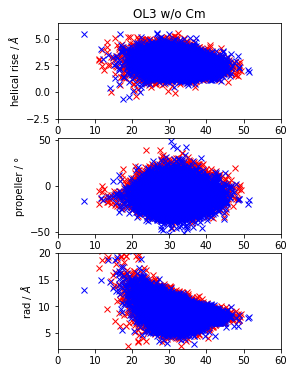

In [40]:
#m_OL3Cm,b_OL3Cm,r_OL3Cm,p_OL3Cm,stderr_OL3Cm= linregress(avg_OL3Cmtwist,avg_OL3Cmrise)
#m_OL3,b_OL3,r_OL3,p_OL3,stderr_OL3= linregress(avg_OL3twist,avg_OL3rise)

cudof = 0
timeskip = 1
plt.figure(figsize=(4,6))
subplot(3,1,1);   
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmrise.shape[1]-cudof,timeskip)],avg_OL3Cmrise[0:nm,np.arange(0,avg_OL3Cmrise.shape[1]-cudof,timeskip)],'rx');
plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3rise.shape[1]-cudof,timeskip)],avg_OL3rise[0:nm,np.arange(0,avg_OL3rise.shape[1]-cudof,timeskip)],'bx');


plt.title('OL3 w/o Cm'); plt.ylabel('helical rise / $\AA$');
plt.axis([0, 60, -2.5, 6.5])

subplot(3,1,2);  
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],avg_OL3Cmpropeller[0:nm,np.arange(0,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],'rx');
plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3propeller.shape[1]-cudof,timeskip)],avg_OL3propeller[0:nm,np.arange(0,avg_OL3propeller.shape[1]-cudof,timeskip)],'bx');

  
plt.ylabel('propeller / °');
plt.axis([0, 60, -52, 52]); 
subplot(3,1,3);    
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],avg_OL3Cmradius1[0:nm,np.arange(0,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],'rx');
plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3radius1.shape[1]-cudof,timeskip)],avg_OL3radius1[0:nm,np.arange(0,avg_OL3radius1.shape[1]-cudof,timeskip)],'bx');
plt.ylabel('rad / $\AA$');
  

plt.axis([0, 60, 2,20])

fignom = "OL3_Cm_RNA15_correlations_no_averaging_Cm_red_withoug_blue_range_%d_%d_200ns.png" %(rangen[0],rangen[1])
plt.savefig(fignom,dpi=1200)




/tmp/ipykernel_5667/1582043291.py:28: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  subplot(3,1,1);
/tmp/ipykernel_5667/1582043291.py:31: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  subplot(3,1,2);
/tmp/ipykernel_5667/1582043291.py:34: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and re

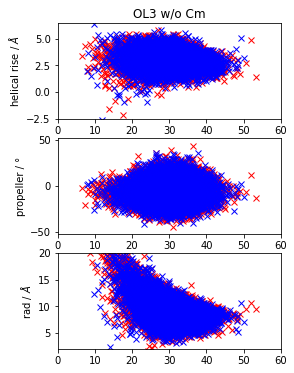

In [21]:
#m_OL3Cm,b_OL3Cm,r_OL3Cm,p_OL3Cm,stderr_OL3Cm= linregress(avg_OL3Cmtwist,avg_OL3Cmrise)
#m_OL3,b_OL3,r_OL3,p_OL3,stderr_OL3= linregress(avg_OL3twist,avg_OL3rise)

cudof = 4500
timeskip = 1
plt.figure(figsize=(4,6))
subplot(3,1,1);   
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmrise.shape[1]-cudof,timeskip)],avg_OL3Cmrise[0:nm,np.arange(0,avg_OL3Cmrise.shape[1]-cudof,timeskip)],'rx');
#plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3rise.shape[1]-cudof,timeskip)],avg_OL3rise[0:nm,np.arange(0,avg_OL3rise.shape[1]-cudof,timeskip)],'bx');
plt.title('OL3 w/o Cm'); plt.ylabel('helical rise / $\AA$');
plt.axis([0, 60, -2.5, 6.5])

subplot(3,1,2);  
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],avg_OL3Cmpropeller[0:nm,np.arange(0,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],'rx');
#plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3propeller.shape[1]-cudof,timeskip)],avg_OL3propeller[0:nm,np.arange(0,avg_OL3propeller.shape[1]-cudof,timeskip)],'bx');
plt.ylabel('propeller / °');
plt.axis([0, 60, -52, 52]); 

subplot(3,1,3);    
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(0,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],avg_OL3Cmradius1[0:nm,np.arange(0,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],'rx');
#plt.plot(avg_OL3twist[0:nm,np.arange(0,avg_OL3radius1.shape[1]-cudof,timeskip)],avg_OL3radius1[0:nm,np.arange(0,avg_OL3radius1.shape[1]-cudof,timeskip)],'bx');
plt.ylabel('rad / $\AA$');

start = 4500
cudof = 0
timeskip = 1
#plt.figure(figsize=(4,6))
subplot(3,1,1);   
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(start,avg_OL3Cmrise.shape[1]-cudof,timeskip)],avg_OL3Cmrise[0:nm,np.arange(start,avg_OL3Cmrise.shape[1]-cudof,timeskip)],'bx');

subplot(3,1,2);  
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(start,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],avg_OL3Cmpropeller[0:nm,np.arange(start,avg_OL3Cmpropeller.shape[1]-cudof,timeskip)],'bx');

subplot(3,1,3);    
plt.plot(avg_OL3Cmtwist[0:nm,np.arange(start,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],avg_OL3Cmradius1[0:nm,np.arange(start,avg_OL3Cmradius1.shape[1]-cudof,timeskip)],'bx');
 

plt.axis([0, 60, 2,20])

fignom = "OL3_Cm_correlations_no_averaging_Cm_red_withoug_blue_range_%d_%d.png" %(rangen[0],rangen[1])
#plt.savefig(fignom,dpi=1200)




In [356]:
table = [['twist',str(round(mean(avg_OL3twist),1))            +u" \u00B1 "+str(round(np.std(avg_OL3twist),1))      ,str(round(mean(avg_OL3Cmtwist),1))     +u" \u00B1 "+str(round(np.std(avg_OL3Cmtwist),1))  ],\
            ['h-rise' ,str(round(mean(avg_OL3rise),2))        +u" \u00B1 "+str(round(np.std(avg_OL3rise),1))       ,str(round(mean(avg_OL3Cmrise),2))      +u" \u00B1 "+str(round(np.std(avg_OL3Cmrise),1)) ],\
            ['propeller',str(round(mean(avg_OL3propeller),1)) +u" \u00B1 "+str(round(np.std(avg_OL3propeller),1))  ,str(round(mean(avg_OL3Cmpropeller),1)) +u" \u00B1 "+str(round(np.std(avg_OL3Cmpropeller),1))  ],\
            ['rad', str(round(mean(avg_OL3radius1),2))        +u" \u00B1 "+str(round(np.std(avg_OL3radius1),1))    ,str(round(mean(avg_OL3Cmradius1),2))   +u" \u00B1 "+str(round(np.std(avg_OL3Cmradius1),1))  ],\
            ['inc'  ,str(round(mean(avg_OL3inc),1))           +u" \u00B1 "+str(round(np.std(avg_OL3inc),1))        ,str(round(mean(avg_OL3Cminc),1))       +u" \u00B1 "+str(round(np.std(avg_OL3Cminc),1))  ]]
print(tabulate( table,headers=['','OL3','OL3 Cm'])) 

nom = "OL3_Cm_table_no_averaging_range_%d_%d.txt" %(rangen[0],rangen[1])
with open(nom, 'w') as f:
    f.write(tabulate(table,headers=['','OL3','OL3 Cm']))
    f.write('\n\ntwist-stretch correlation slope'+'\nOL3: '+str(round(m_OL3,3)) + '\nOL3 Cm: '+str(round(m_OL3Cm,3)))

           OL3          OL3 Cm
---------  -----------  ----------
twist      31.7 ± 4.0   30.4 ± 4.2
h-rise     2.84 ± 0.5   2.98 ± 0.6
propeller  -11.0 ± 9.1  -6.7 ± 9.6
rad        8.71 ± 1.4   9.06 ± 1.8
inc        11.6 ± 11.2  8.8 ± 11.7


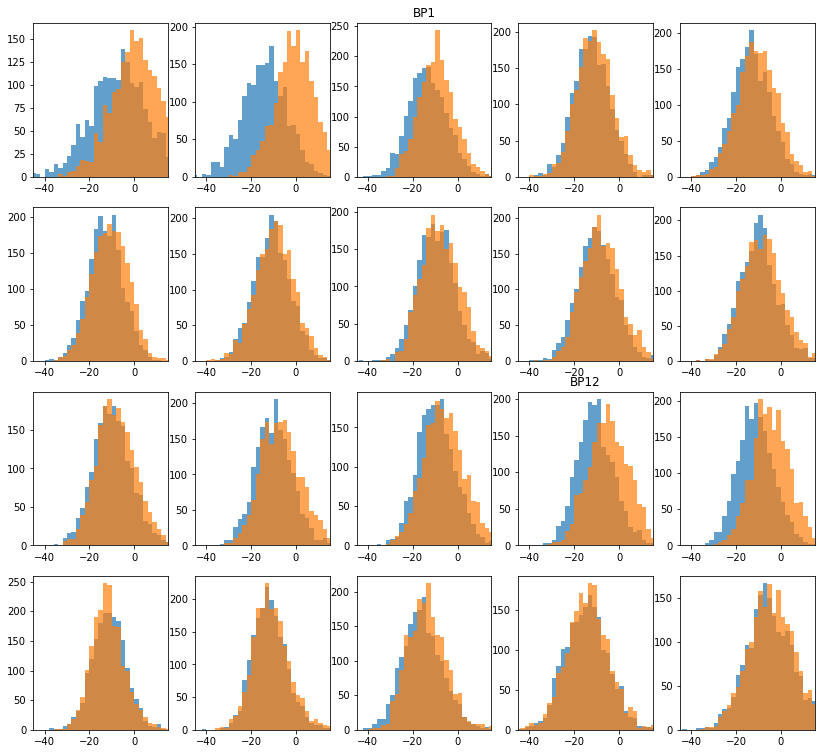

In [7]:
#fig,ax = plt.subplots(3,4,figsize=(8,8))
bns_prop =np.linspace(-60,60,61)
plt.figure(figsize=(14,13))


for bp in range(20):
    subplot(4,5,bp+1);  
    hist(OL3propeller[bp],bins=bns_prop,alpha = 0.7);
    hist(OL3Cmpropeller[bp][1:2000],bins=bns_prop,alpha = 0.7);
    #hist(OL3Cmpropeller[bp][4000:6500],bins=bns_prop,alpha = 0.7);
    #plt.plot([mean(OL3propeller[bp]),mean(OL3propeller[bp])], [0,220], "b--")
    #plt.plot([mean(OL3Cmpropeller[bp]),mean(OL3Cmpropeller[bp])], [0,220], "--",color ="red")
    
    plt.xlim([-45,15])
    
subplot(4,5,3);plt.title('BP1')
subplot(4,5,14);plt.title('BP12')

fignom = "OL3_BP_propeller_hist.png" 
#plt.savefig(fignom,dpi=1200)


In [7]:
# Umschreiben mit anderer Step size... (1ns)

dateenamee = "_marcel_sim/OL3_odd_MHrun/L-BP_oddMHrun.dat"

numb = "# Time ="#'99.99'
liste = np.array([])

with open(dateenamee) as myFile:
    for num, line in enumerate(myFile, 1):
        if numb in line:
            liste = np.append(liste,num)

diffe = np.diff(liste)
#result = np.where(diffe == 20) #for base pair steps
result = np.where(diffe == 21) #for base pairs
result = result[0]

for x in result:
    if x==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>0 and x<10:
        srch = '# Time =      '+str(x*10)+'00.00000'
        rplc = '# Time =      '+str(x*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>9 and x<100:
        srch = '# Time =     '+str(x*10)+'00.00000'
        rplc = '# Time =     '+str(x*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>99 and x<1000:
        srch = '# Time =    '+str(x*10)+'00.00000'
        rplc = '# Time =    '+str(x*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>999 and x<10000:
        srch = '# Time =   '+str(x*10)+'00.00000'
        rplc = '# Time =   '+str(x*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')
            
#result19 = np.where(diffe == 19) #for base pair steps
result19 = np.where(diffe == 20) #for base pairs
result19 = result19[0]

for y in result19:
    if y==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>0 and y<10:
        srch = '# Time =       '+str(y*10)+'00.00000'
        rplc = '# Time =       '+str(y*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>9 and y<100:
        srch = '# Time =      '+str(y*10)+'00.00000'
        rplc = '# Time =      '+str(y*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>99 and y<1000:
        srch = '# Time =     '+str(y*10)+'00.00000'
        rplc = '# Time =     '+str(y*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>999 and y<10000:
        srch = '# Time =    '+str(y*10)+'00.00000'
        rplc = '# Time =    '+str(y*10)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')